## **MSCFE CAPSTONE PROJECT:  TIME SERIES APPROACH TO MODEL VOLATILITY OF EMERGING MARKETS - CASE OF MALAWI**

In [7]:
from pathlib import Path
import sys

sys.path.insert(0, str(Path.cwd().parent))

print(Path.cwd().parent)

C:\Users\DELL i7\Desktop\Capstone-Project


In [13]:
# Import libraries
import importlib
import src.data_inspection
importlib.reload(src.data_inspection)

# Data manipulation
import numpy as np
import pandas as pd 

# Visualization 
import matplotlib.pyplot as plt

# Statistical analysis
import statsmodels.api as sm
import pylab
import scipy.stats as stats
from scipy.stats import norm, shapiro, anderson, kstest, normaltest
from statsmodels.stats.diagnostic import het_arch


# Quite warnings
import warnings
warnings.filterwarnings("ignore")

## **1. Exploratory Data Analysis**

In [14]:
# Load data
masi_df = pd.read_csv("../data/masi_df.csv", parse_dates=["Date"], index_col="Date")
masi_df["MASI"] = masi_df["MASI"].interpolate(method="linear") # 14 obv were missing in original df
masi_df["log_ret"] = np.log(masi_df["MASI"] / masi_df["MASI"].shift(1)) # Log returns
masi_r = masi_df["log_ret"].dropna() # Extract Series

# Inspect the returns
src.data_inspection.inspect_data(masi_r)

LOG RETURN DIAGNOSTICS
------------------------------------------
Start date: 2018-06-14 00:00:00
End date: 2026-05-13 00:00:00
Frequency: Daily [Trading_Days]
------------------------------------------
Summary statistics:
count    1723.000000
mean        0.001638
std         0.007461
min        -0.062805
25%        -0.000163
50%         0.000000
75%         0.001847
max         0.049205
Name: log_ret, dtype: float64
------------------------------------------
Distribution:
Skewness: 0.9834
Excess Kurtosis: 11.6178
Jarque-Bera p-value: 0.0000
Decision: Reject H0 : Non-normality
Shapiro-Wilk p-value: 0.0000
Decision: Reject H0 : Non-normality
ADF p-value: 0.0000
Decision: Reject H0 :Stationary
KPSS p-value: 0.0100
Decision: Reject H0 : Non-stationary
------------------------------------------


### **1.1.  Returns Time Series Plots**

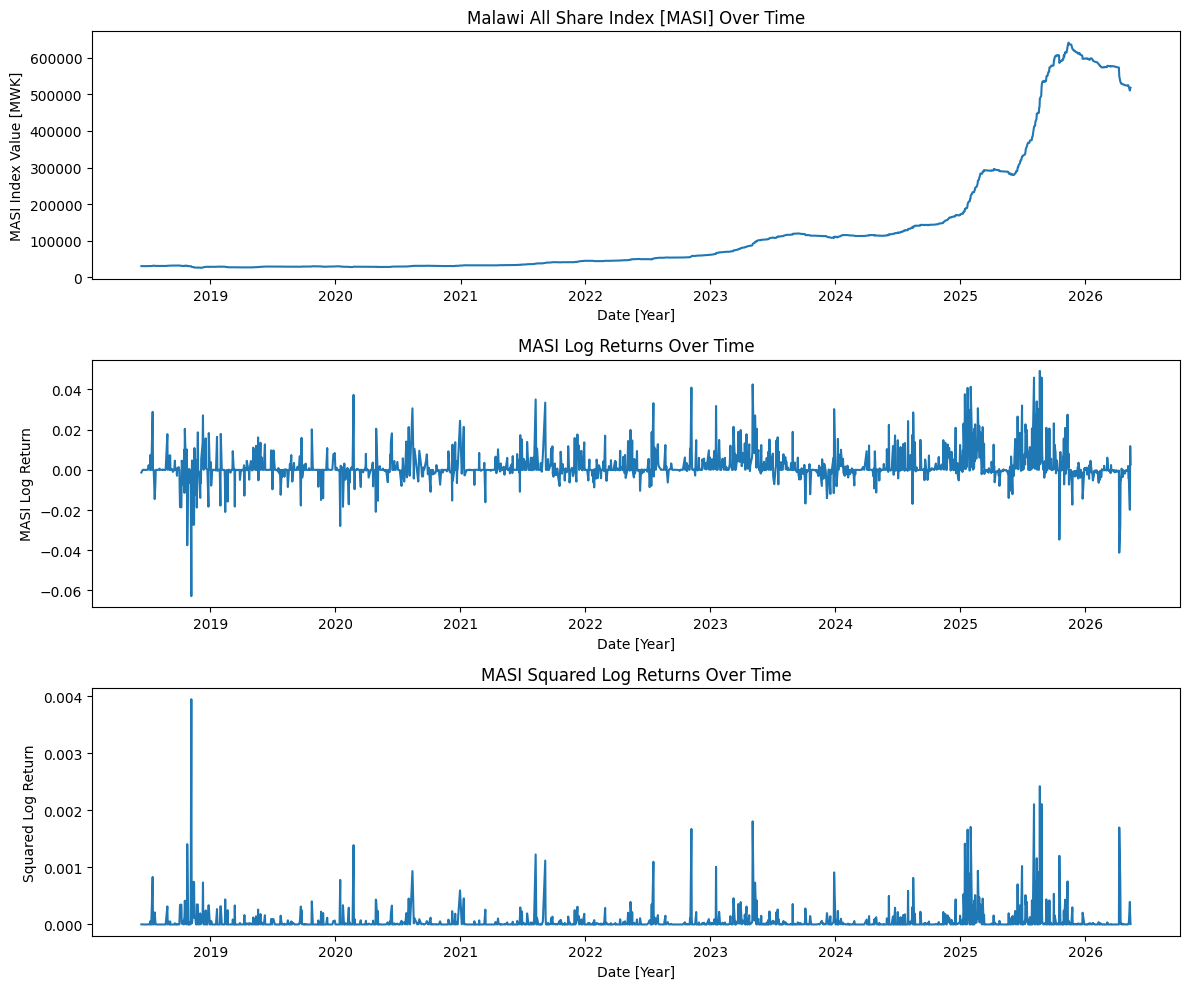

In [15]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10))

# Raw MASI index
axes[0].plot(masi_df.index, masi_df['MASI'])
axes[0].set_xlabel('Date [Year]')
axes[0].set_ylabel('MASI Index Value [MWK]')
axes[0].set_title('Malawi All Share Index [MASI] Over Time')

# Log returns
axes[1].plot(masi_df.index, masi_df['log_ret'])
axes[1].set_xlabel('Date [Year]')
axes[1].set_ylabel('MASI Log Return')
axes[1].set_title('MASI Log Returns Over Time')

# Squared returns (volatility proxy)
axes[2].plot(masi_df.index, masi_df['log_ret'] ** 2)
axes[2].set_xlabel('Date [Year]')
axes[2].set_ylabel('Squared Log Return')
axes[2].set_title('MASI Squared Log Returns Over Time')

plt.tight_layout()
plt.show()


### **1.1.  Returns Distribution Plots**

1. Sturges' rule: $k = 1 + \text{log}_2(n)$
2. Square-root rule: $k = \sqrt{n}$
3. Rice rule: $k = 2 \cdot n^{1/3}$
4. Freedman-Diaconis rule:
   $h = 2 \frac{IQR(x)}{n^{1/3}}$ then $k = \frac{\text{max}(x) - \text{min}(x)}{h}$
5. Scott's rule:
   $h = 3.5 \frac{\sigma(x)}{n^{1/3}}$ then $k = \frac{\text{max}(x) - \text{min}(x)}{h}$

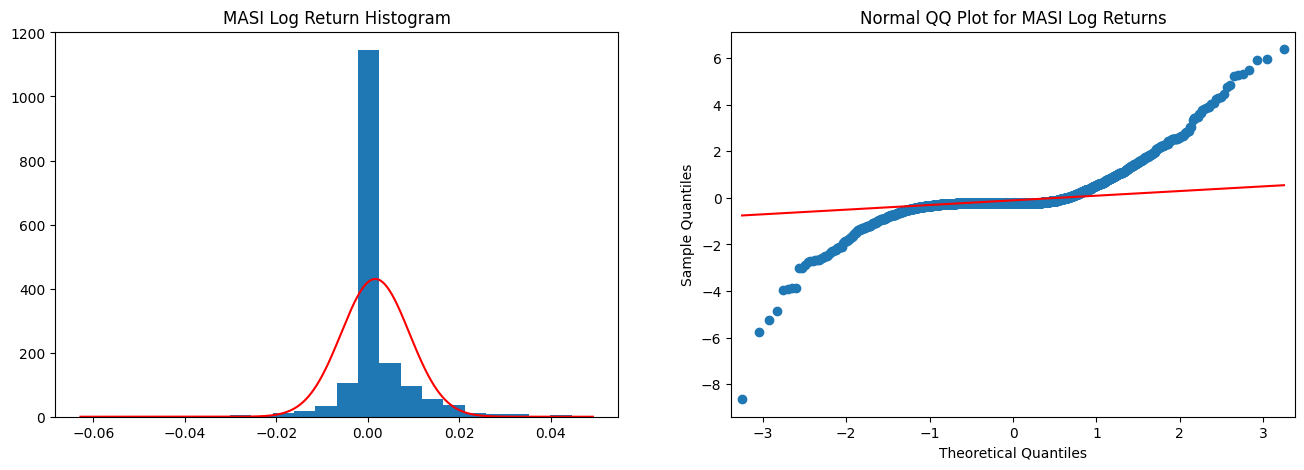

In [16]:
# Histogram and Normal QQ Plot for MASI Log Returns
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
masi_r = masi_df["log_ret"].dropna()

# Histogram with density
x = np.linspace(min(masi_r), max(masi_r), len(masi_r))
(mu, sigma) = stats.norm.fit(masi_r)
values, bins, _ = ax1.hist(masi_r, bins=24)  # Histogram
ax1.plot(x,stats.norm.pdf(x, mu, sigma) * sum(values * np.diff(bins)), "r")  # Density
ax1.set(title="MASI Log Return Histogram")

# Normal QQ plot
sm.qqplot(masi_r, stats.norm, fit=True, line="q", ax=ax2)
ax2.set(title="Normal QQ Plot for MASI Log Returns")

plt.show()

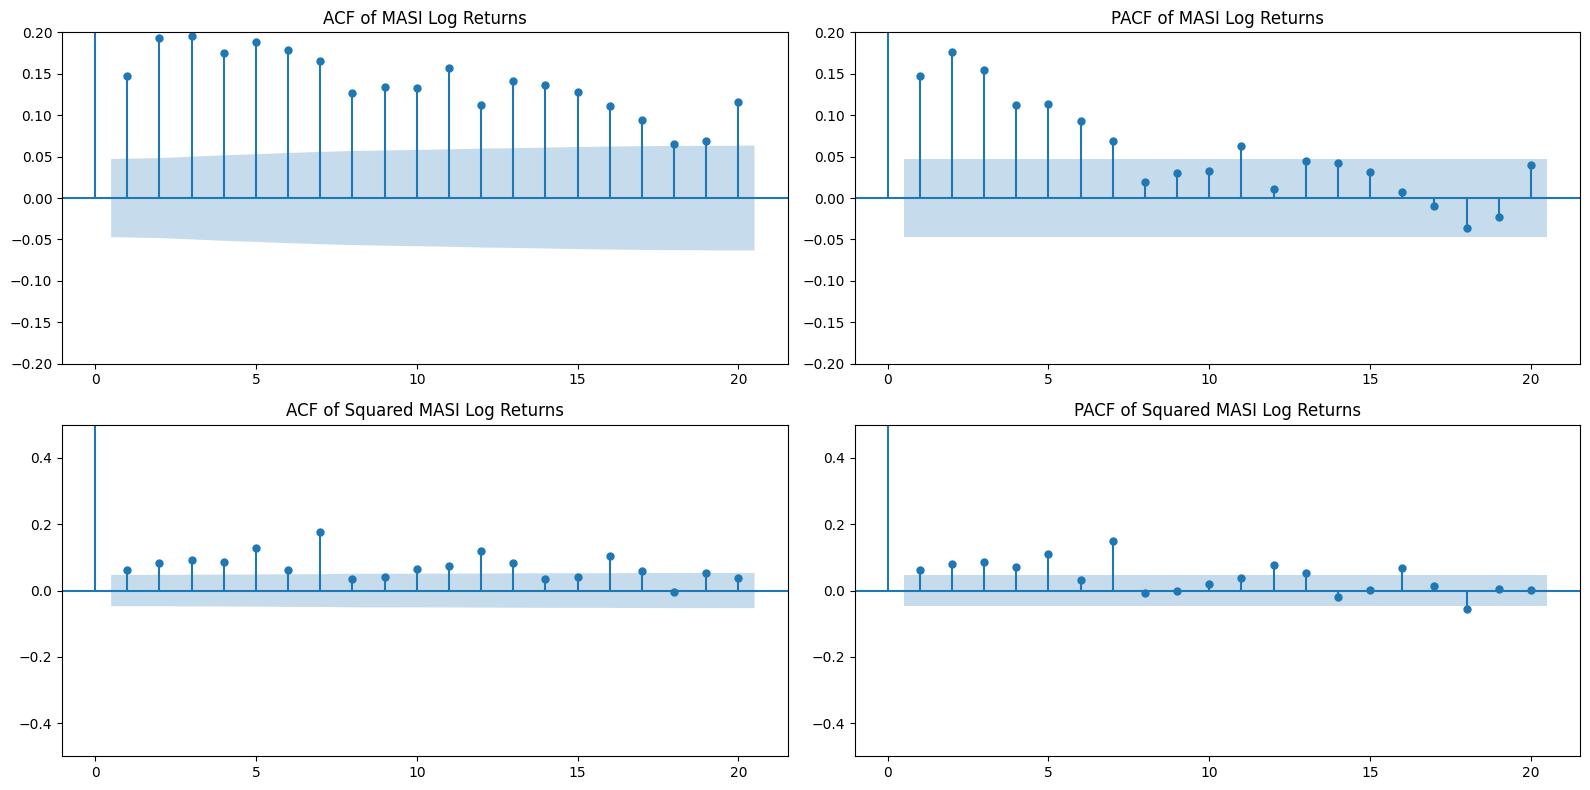

In [17]:

fig, axes = plt.subplots(2, 2, figsize=(16, 8))

# Top row: Raw MASI Log Returns
sm.graphics.tsa.plot_acf(masi_r, lags=20, ax=axes[0, 0])
axes[0, 0].set(title="ACF of MASI Log Returns", ylim=[-0.2, 0.2])

sm.graphics.tsa.plot_pacf(masi_r, lags=20, ax=axes[0, 1])
axes[0, 1].set(title="PACF of MASI Log Returns", ylim=[-0.2, 0.2])

# Bottom row: Squared MASI Log Returns
sm.graphics.tsa.plot_acf(masi_r ** 2, lags=20, ax=axes[1, 0])
axes[1, 0].set(title="ACF of Squared MASI Log Returns", ylim=[-0.5, 0.5])

sm.graphics.tsa.plot_pacf(masi_r ** 2, lags=20, ax=axes[1, 1])
axes[1, 1].set(title="PACF of Squared MASI Log Returns", ylim=[-0.5, 0.5])

plt.tight_layout()
plt.show()

In [18]:
# Run Engle's ARCH LM test
lm_stat, p_value, f_stat, f_pvalue = het_arch(masi_r.dropna(), nlags=10)

print(f"Engle's ARCH LM Test:")
print(f"  LM Statistic: {lm_stat:.4f}")
print(f"  p-value:      {p_value:.4f}")
print(f"  F-statistic:  {f_stat:.4f}")
print(f"  F p-value:    {f_pvalue:.4f}")

if p_value < 0.05:
    print("\n Reject H0: ARCH effects are present. Use GARCH.")
else:
    print("\n Fail to reject H0: No significant ARCH effects. GARCH not needed.")

Engle's ARCH LM Test:
  LM Statistic: 96.9885
  p-value:      0.0000
  F-statistic:  10.2149
  F p-value:    0.0000

 Reject H0: ARCH effects are present. Use GARCH.


# 2. **Testing for Stationality** 

In [19]:
print(type(masi_r))

<class 'pandas.core.series.Series'>


## 2. Models

In [20]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from arch import arch_model
from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox

plt.rcParams["figure.figsize"] = (16, 9)  # Figure size and width

In [21]:
# GARCH(1,1) Model with Normal White Noise
garch11_spec = arch_model(
    masi_r.dropna(),
    vol="GARCH",
    p=1,
    q=1,
    mean="AR",
    dist="Normal",
    rescale=True,
)
garch11_fit = garch11_spec.fit()
garch11_fit.summary()

Iteration:      1,   Func. Count:      6,   Neg. LLF: 196484478.5713515
Iteration:      2,   Func. Count:     15,   Neg. LLF: 268670.0986841089
Iteration:      3,   Func. Count:     22,   Neg. LLF: 2053.7751702948785
Iteration:      4,   Func. Count:     28,   Neg. LLF: 3503.9972062405204
Iteration:      5,   Func. Count:     36,   Neg. LLF: 1833.945403021429
Iteration:      6,   Func. Count:     42,   Neg. LLF: 2074.4387373535446
Iteration:      7,   Func. Count:     48,   Neg. LLF: 1815.3189729678152
Iteration:      8,   Func. Count:     54,   Neg. LLF: 1796.5185084133025
Iteration:      9,   Func. Count:     60,   Neg. LLF: 1792.7742334948944
Iteration:     10,   Func. Count:     65,   Neg. LLF: 1792.768151149113
Iteration:     11,   Func. Count:     70,   Neg. LLF: 1792.7680995453093
Iteration:     12,   Func. Count:     75,   Neg. LLF: 1792.7680985006173
Iteration:     13,   Func. Count:     79,   Neg. LLF: 1792.7680985014965
Optimization terminated successfully    (Exit mode 0)
 

<class 'statsmodels.iolib.summary.Summary'>
"""
                           AR - GARCH Model Results                           
==============================================================================
Dep. Variable:                log_ret   R-squared:                       0.000
Mean Model:                        AR   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -1792.77
Distribution:                  Normal   AIC:                           3593.54
Method:            Maximum Likelihood   BIC:                           3615.34
                                        No. Observations:                 1723
Date:                Mon, Sep 21 2026   Df Residuals:                     1722
Time:                        21:34:46   Df Model:                            1
                                Mean Model                                
==========================================================================
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
Const          0.0928  1.860e-02      4.992  5.970e-07 [5.639e-02,  0.129]
                              Volatility Model                              
============================================================================
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
omega          0.0387  1.319e-02      2.931  3.380e-03 [1.281e-02,6.453e-02]
alpha[1]       0.0917  2.989e-02      3.068  2.156e-03   [3.312e-02,  0.150]
beta[1]        0.8416  3.888e-02     21.646 6.605e-104     [  0.765,  0.918]
============================================================================

Covariance estimator: robust
"""

In [22]:
# Diagnostic tests for GARCH(1,1) Model with Normal White Noise
print("GARCH(1,1) Model with Normal White Noise\n")

# Ljung-Box test and the Box-Pierce test
print("Ljung-Box and Box-Pierce tests on stanrdized residuals")
print(acorr_ljungbox(garch11_fit.std_resid, boxpierce=True))

print("\nLjung-Box and Box-Pierce tests on stanrdized squared residuals")
print(acorr_ljungbox(garch11_fit.std_resid**2, boxpierce=True))

# ARCH LM test for conditional heteroskedasticity
print("\nARCH LM test for conditional heteroskedasticity")
print(garch11_fit.arch_lm_test(standardized=True))

GARCH(1,1) Model with Normal White Noise

Ljung-Box and Box-Pierce tests on stanrdized residuals
       lb_stat     lb_pvalue     bp_stat     bp_pvalue
1    12.480274  4.112719e-04   12.458569  4.160786e-04
2    39.779448  2.301456e-09   39.694440  2.401385e-09
3    70.132474  3.998449e-15   69.959487  4.354453e-15
4    97.908127  2.742149e-20   97.638529  3.129393e-20
5   121.392698  1.591131e-24  121.027801  1.901137e-24
6   150.875758  5.051345e-30  150.374127  6.448823e-30
7   168.169305  6.104697e-33  167.577447  8.135840e-33
8   180.162963  9.514959e-35  179.501576  1.310048e-34
9   201.470116  1.629328e-38  200.672858  2.394224e-38
10  212.232430  4.505602e-40  211.360304  6.855643e-40

Ljung-Box and Box-Pierce tests on stanrdized squared residuals
     lb_stat  lb_pvalue   bp_stat  bp_pvalue
1   0.043707   0.834399  0.043631   0.834541
2   0.186409   0.911007  0.186002   0.911192
3   0.527524   0.912804  0.526128   0.913115
4   0.547656   0.968699  0.546190   0.968851
5   0.676

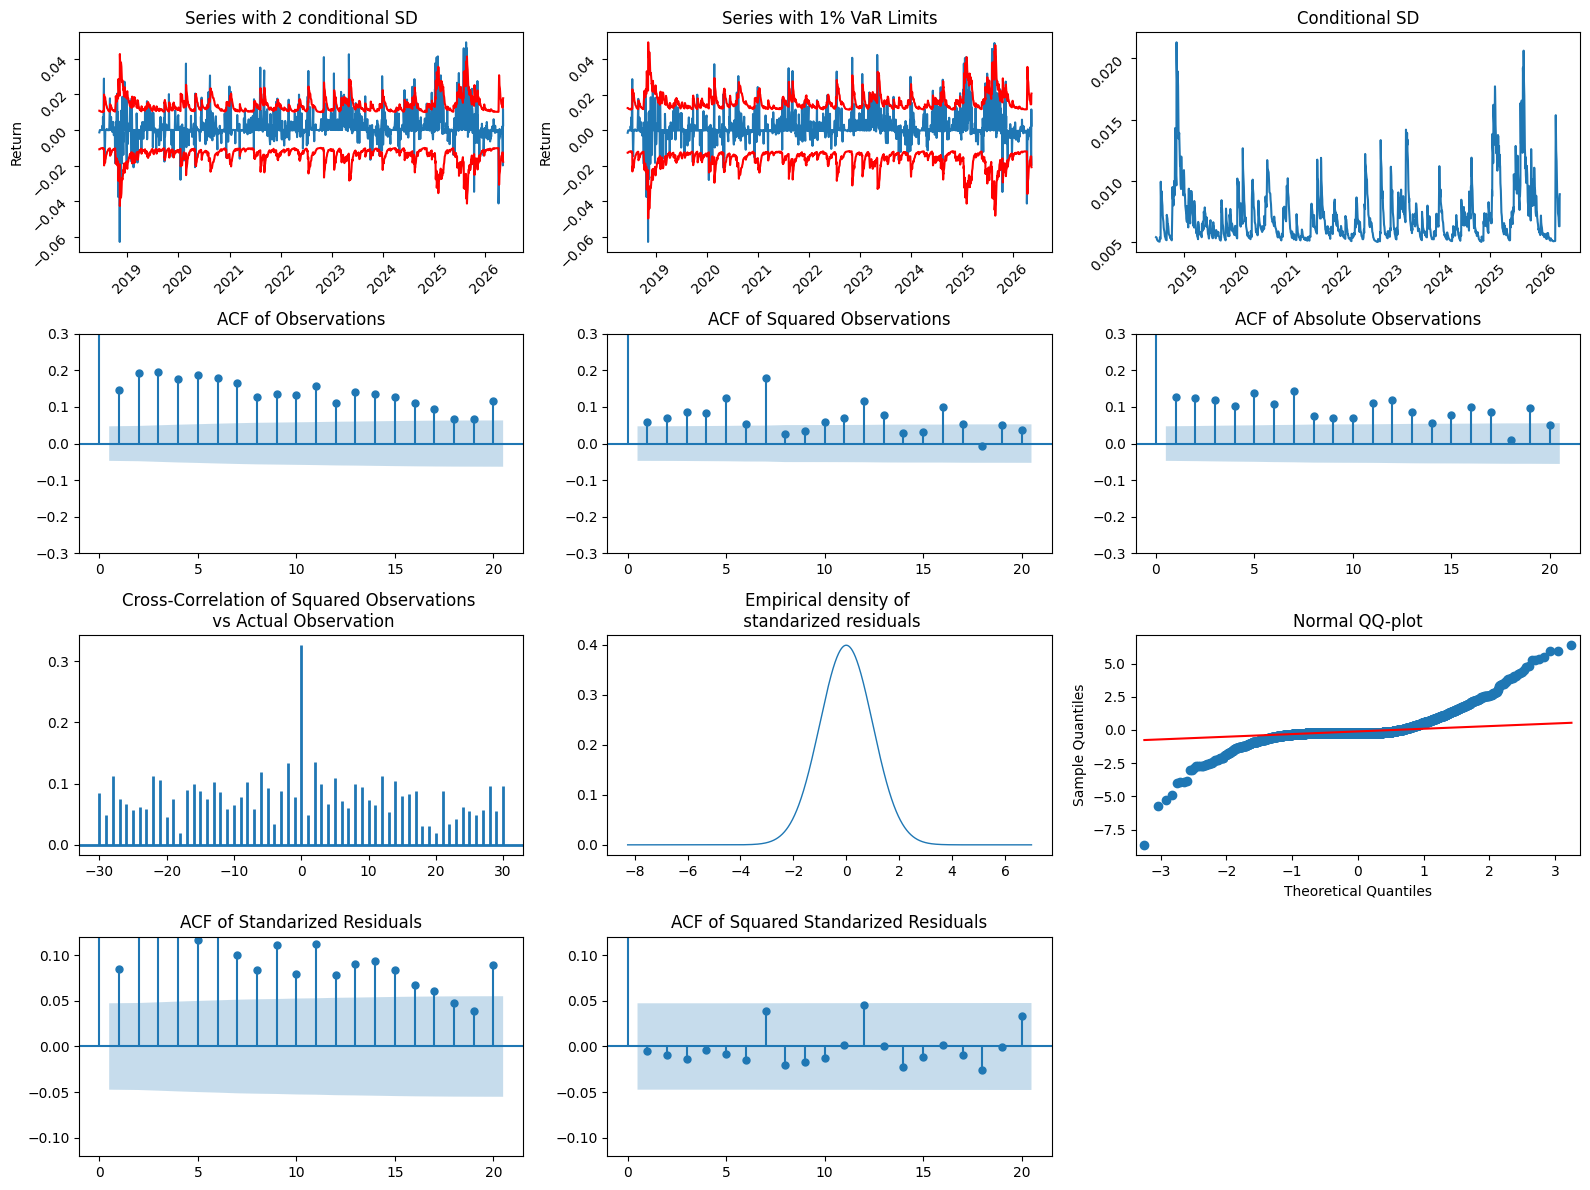

In [23]:
# Model Diagnostic Plots for the GARCH(1,1) Model with Normal White Noise
fig, ax = plt.subplots(4, 3, figsize=(16, 12))

# Figure Row 1 Column 1
ax[0, 0].plot(masi_r)
ax[0, 0].plot(2.0 * garch11_fit.conditional_volatility / 100.0, c="r")
ax[0, 0].plot(-2.0 * garch11_fit.conditional_volatility / 100.0, c="r")
ax[0, 0].tick_params(labelrotation=45)
ax[0, 0].set_title("Series with 2 conditional SD")
ax[0, 0].set_ylabel("Return")

# Figure Row 1 Column 2
VaR_1 = stats.norm.ppf(0.99)
ax[0, 1].plot(masi_r)
ax[0, 1].plot(VaR_1 * garch11_fit.conditional_volatility / 100.0, c="r")
ax[0, 1].plot(-VaR_1 * garch11_fit.conditional_volatility / 100.0, c="r")
ax[0, 1].tick_params(labelrotation=45)
ax[0, 1].set_title("Series with 1% VaR Limits")
ax[0, 1].set_ylabel("Return")

# Figure Row 1 Column 3
ax[0, 2].plot(garch11_fit.conditional_volatility / 100.0)
ax[0, 2].set_title("Conditional SD")
ax[0, 2].tick_params(labelrotation=45)

# Figure Row 2 Column 1
sm.graphics.tsa.plot_acf(garch11_fit.resid / 100.0, lags=20, ax=ax[1, 0])
ax[1, 0].set_title("ACF of Observations")
ax[1, 0].set_ylim([-0.3, 0.3])

# Figure Row 2 Column 2
sm.graphics.tsa.plot_acf(garch11_fit.resid**2, lags=20, ax=ax[1, 1])
ax[1, 1].set_title("ACF of Squared Observations")
ax[1, 1].set_ylim([-0.3, 0.3])

# Figure Row 2 Column 3
sm.graphics.tsa.plot_acf(np.abs(garch11_fit.resid), lags=20, ax=ax[1, 2])
ax[1, 2].set_title("ACF of Absolute Observations")
ax[1, 2].set_ylim([-0.3, 0.3])

# Figure Row 3 Column 1
ax[2, 0].xcorr(
    garch11_fit.resid**2,
    garch11_fit.resid,
    usevlines=True,
    maxlags=30,
    normed=True,
    lw=2,
)
ax[2, 0].set_title("Cross-Correlation of Squared Observations \n vs Actual Observation")

# Figure Row 3 Column 2
standaraized_residuals = garch11_fit.std_resid
min_val = np.min(standaraized_residuals)
max_val = np.max(standaraized_residuals)
empirical_density = np.linspace(min_val, max_val, len(standaraized_residuals))
ax[2, 1].plot(empirical_density, stats.norm.pdf(empirical_density), lw=1)
ax[2, 1].set_title("Empirical density of \n standarized residuals")

# Figure Row 3 Column 3
sm.qqplot(garch11_fit.resid, stats.norm, fit=True, line="q", ax=ax[2, 2])
ax[2, 2].set_title("Normal QQ-plot")

# Figure Row 4 Column 1
sm.graphics.tsa.plot_acf(garch11_fit.std_resid, lags=20, ax=ax[3, 0])
ax[3, 0].set_title("ACF of Standarized Residuals")
ax[3, 0].set_ylim([-0.12, 0.12])

# Figure Row 4 Column 2
sm.graphics.tsa.plot_acf((garch11_fit.std_resid) ** 2, lags=20, ax=ax[3, 1])
ax[3, 1].set_title("ACF of Squared Standarized Residuals")
ax[3, 1].set_ylim([-0.12, 0.12])

ax[3, 2].axis("off")
fig.tight_layout()
plt.show()

## 2.1 improvements 

In [24]:
# GARCH(1,1) Model with Student's t White Noise
garch11_t_spec = arch_model(
    masi_r.dropna(),
    vol="GARCH",
    p=1,
    q=1,
    mean="AR",
    dist="StudentsT",  # power=2.0,
    rescale=True,
)
garch11_t_fit = garch11_t_spec.fit()
garch11_t_fit.summary()

Iteration:      1,   Func. Count:      7,   Neg. LLF: 67178.46084713191
Iteration:      2,   Func. Count:     21,   Neg. LLF: 19876.202736199208
Iteration:      3,   Func. Count:     28,   Neg. LLF: 18838.552937075194
Iteration:      4,   Func. Count:     35,   Neg. LLF: 1747.3493597298595
Iteration:      5,   Func. Count:     42,   Neg. LLF: 2895.5976177509947
Iteration:      6,   Func. Count:     49,   Neg. LLF: 2427.0148021642262
Iteration:      7,   Func. Count:     56,   Neg. LLF: 1177.2363094392895
Iteration:      8,   Func. Count:     63,   Neg. LLF: 1635.5116194644395
Iteration:      9,   Func. Count:     70,   Neg. LLF: 2154.425057535283
Iteration:     10,   Func. Count:     77,   Neg. LLF: 2389.816443551739
Iteration:     11,   Func. Count:     84,   Neg. LLF: 1247.2907216479514
Iteration:     12,   Func. Count:     91,   Neg. LLF: 1344.0367196797672
Iteration:     13,   Func. Count:     98,   Neg. LLF: 1205.6352377298247
Iteration:     14,   Func. Count:    105,   Neg. LLF: 

<class 'statsmodels.iolib.summary.Summary'>
"""
                              AR - GARCH Model Results                              
====================================================================================
Dep. Variable:                      log_ret   R-squared:                       0.000
Mean Model:                              AR   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -926.060
Distribution:      Standardized Student's t   AIC:                           1862.12
Method:                  Maximum Likelihood   BIC:                           1889.38
                                              No. Observations:                 1723
Date:                      Mon, Sep 21 2026   Df Residuals:                     1722
Time:                              21:34:48   Df Model:                            1
                                  Mean Model                                 
=============================================================================
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
Const      2.0284e-03  2.624e-03      0.773      0.440 [-3.115e-03,7.172e-03]
                               Volatility Model                              
=============================================================================
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
omega          0.0329  1.712e-02      1.924  5.436e-02 [-6.160e-04,6.649e-02]
alpha[1]       0.3245  5.453e-02      5.951  2.672e-09      [  0.218,  0.431]
beta[1]        0.6755  8.329e-02      8.111  5.035e-16      [  0.512,  0.839]
                              Distribution                              
========================================================================
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
nu             2.1226  1.865e-02    113.832      0.000 [  2.086,  2.159]
========================================================================

Covariance estimator: robust
"""

In [25]:
# Diagnostic tests for GARCH(1,1) Model with Student's t White Noise
print("GARCH(1,1) Model with StudentsT White Noise\n")

# Ljung-Box test and the Box-Pierce test
print("Ljung-Box and Box-Pierce tests on stanrdized residuals")
print(acorr_ljungbox(garch11_t_fit.std_resid, boxpierce=True))

print("\nLjung-Box and Box-Pierce tests on stanrdized squared residuals")
print(acorr_ljungbox(garch11_t_fit.std_resid**2, boxpierce=True))

# ARCH LM test for conditional heteroskedasticity
print("\nARCH LM test for conditional heteroskedasticity for")
print(garch11_t_fit.arch_lm_test(standardized=True))

GARCH(1,1) Model with StudentsT White Noise

Ljung-Box and Box-Pierce tests on stanrdized residuals
      lb_stat     lb_pvalue    bp_stat     bp_pvalue
1    3.223548  7.258616e-02   3.217941  7.283517e-02
2   14.599631  6.756635e-04  14.567645  6.865561e-04
3   26.351555  8.050203e-06  26.285506  8.310776e-06
4   40.487089  3.432159e-08  40.371873  3.625825e-08
5   49.129594  2.087938e-09  48.979307  2.240969e-09
6   64.480856  5.506252e-12  64.259375  6.110183e-12
7   69.461341  1.898154e-12  69.213874  2.129640e-12
8   74.422725  6.436412e-13  74.146497  7.309959e-13
9   87.023643  6.427694e-15  86.667061  7.575186e-15
10  91.020540  3.360185e-15  90.636154  4.005426e-15

Ljung-Box and Box-Pierce tests on stanrdized squared residuals
     lb_stat  lb_pvalue   bp_stat  bp_pvalue
1   1.469928   0.225357  1.467372   0.225761
2   2.703328   0.258809  2.697911   0.259511
3   3.800620   0.283814  3.792023   0.284815
4   4.518266   0.340387  4.507173   0.341698
5   5.569452   0.350390  5.5

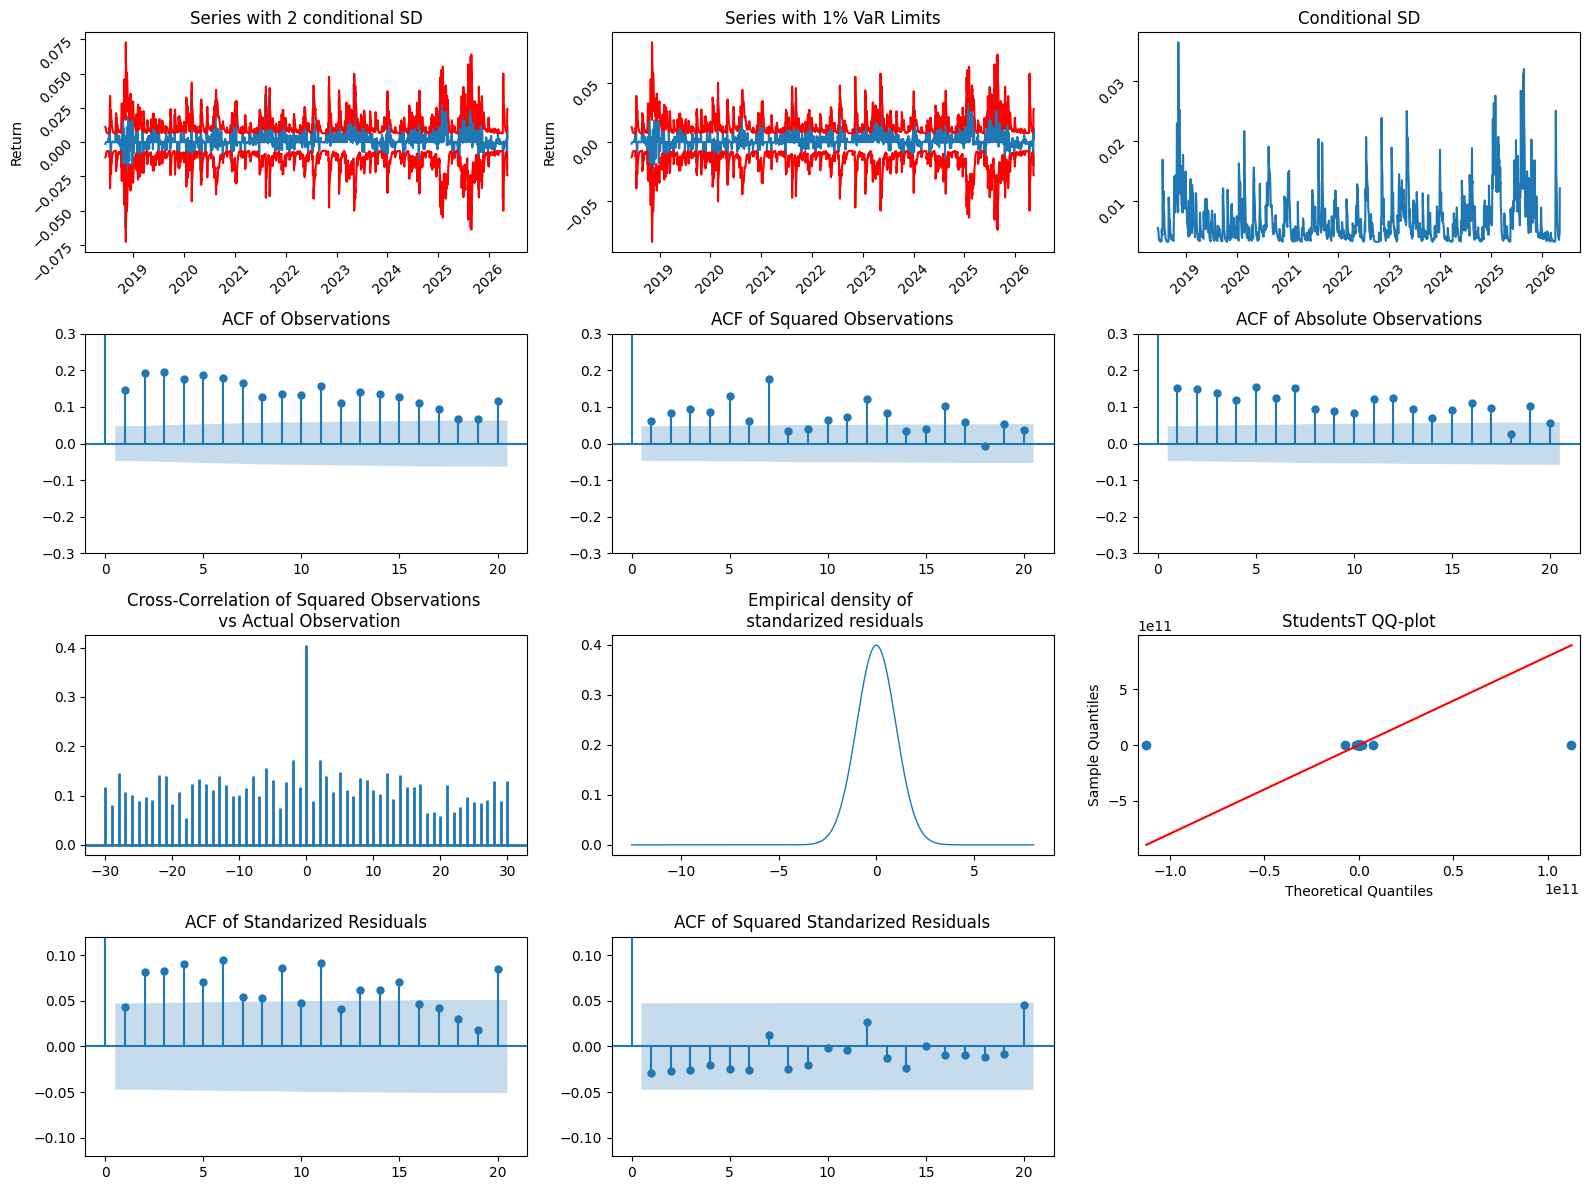

In [26]:
# Model Diagnostic Plots for the GARCH(1,1) Model with Student's t White Noise
fig, ax = plt.subplots(4, 3, figsize=(16, 12))

# Figure Row 1 Column 1
ax[0, 0].plot(masi_r)
ax[0, 0].plot(2.0 * garch11_t_fit.conditional_volatility / 100.0, c="r")
ax[0, 0].plot(-2.0 * garch11_t_fit.conditional_volatility / 100.0, c="r")
ax[0, 0].tick_params(labelrotation=45)
ax[0, 0].set_title("Series with 2 conditional SD")
ax[0, 0].set_ylabel("Return")

# Figure Row 1 Column 2
VaR_1 = stats.t(df=len(masi_r) - 1).ppf(0.99)
# VaR_1 = stats.norm.ppf(0.99)
ax[0, 1].plot(masi_r)
ax[0, 1].plot(VaR_1 * garch11_t_fit.conditional_volatility / 100.0, c="r")
ax[0, 1].plot(-VaR_1 * garch11_t_fit.conditional_volatility / 100.0, c="r")
ax[0, 1].tick_params(labelrotation=45)
ax[0, 1].set_title("Series with 1% VaR Limits")
ax[0, 1].set_ylabel("Return")

# Figure Row 1 Column 3
ax[0, 2].plot(garch11_t_fit.conditional_volatility / 100.0)
ax[0, 2].set_title("Conditional SD")
ax[0, 2].tick_params(labelrotation=45)

# Figure Row 2 Column 1
sm.graphics.tsa.plot_acf(garch11_t_fit.resid / 100.0, lags=20, ax=ax[1, 0])
ax[1, 0].set_title("ACF of Observations")
ax[1, 0].set_ylim([-0.3, 0.3])

# Figure Row 2 Column 2
sm.graphics.tsa.plot_acf(garch11_t_fit.resid**2, lags=20, ax=ax[1, 1])
ax[1, 1].set_title("ACF of Squared Observations")
ax[1, 1].set_ylim([-0.3, 0.3])

# Figure Row 2 Column 3
sm.graphics.tsa.plot_acf(np.abs(garch11_t_fit.resid), lags=20, ax=ax[1, 2])
ax[1, 2].set_title("ACF of Absolute Observations")
ax[1, 2].set_ylim([-0.3, 0.3])

# Figure Row 3 Column 1
ax[2, 0].xcorr(
    garch11_t_fit.resid**2,
    garch11_t_fit.resid,
    usevlines=True,
    maxlags=30,
    normed=True,
    lw=2,
)
ax[2, 0].set_title("Cross-Correlation of Squared Observations \n vs Actual Observation")

# Figure Row 3 Column 2
standaraized_residuals = garch11_t_fit.std_resid
min_val = np.min(standaraized_residuals)
max_val = np.max(standaraized_residuals)
empirical_density = np.linspace(min_val, max_val, len(standaraized_residuals))
ax[2, 1].plot(empirical_density, stats.norm.pdf(empirical_density), lw=1)
ax[2, 1].set_title("Empirical density of \n standarized residuals")

# Figure Row 3 Column 3
sm.qqplot(garch11_t_fit.resid, stats.t, fit=True, line="q", ax=ax[2, 2])
ax[2, 2].set_title("StudentsT QQ-plot")

# Figure Row 4 Column 1
sm.graphics.tsa.plot_acf(garch11_t_fit.std_resid, lags=20, ax=ax[3, 0])
ax[3, 0].set_title("ACF of Standarized Residuals")
ax[3, 0].set_ylim([-0.12, 0.12])

# Figure Row 4 Column 2
sm.graphics.tsa.plot_acf((garch11_t_fit.std_resid) ** 2, lags=20, ax=ax[3, 1])
ax[3, 1].set_title("ACF of Squared Standarized Residuals")
ax[3, 1].set_ylim([-0.12, 0.12])

ax[3, 2].axis("off")
fig.tight_layout()
plt.show()


In [27]:
# 20-Step Ahead Forecast: GARCH(1,1) with Student's t Errors

# Set forecast horizon
horizon = 20

# Generate forecast
garch_forecast = garch11_t_fit.forecast(
    horizon=horizon,
    reindex=False
)

# Extract forecasted mean and variance
forecast_mean = garch_forecast.mean.iloc[-1]
forecast_variance = garch_forecast.variance.iloc[-1]

# Forecasted volatility
forecast_volatility = np.sqrt(forecast_variance)

# Create forecast index
forecast_index = range(1, horizon + 1)

# 95% confidence intervals
z = 1.96

upper_band = forecast_mean + z * forecast_volatility
lower_band = forecast_mean - z * forecast_volatility

# Forecast table
forecast_df = pd.DataFrame({
    "Mean": forecast_mean.values,
    "Variance": forecast_variance.values,
    "Volatility": forecast_volatility.values,
    "Lower 95%": lower_band.values,
    "Upper 95%": upper_band.values
}, index=forecast_index)

forecast_df.index.name = "Horizon"

forecast_df

,Mean,Variance,Volatility,Lower 95%,Upper 95%
Horizon,,,,,
1,0.002028,1.047715,1.023580,-2.004188,2.008244
2,0.002028,1.080652,1.039544,-2.035478,2.039534
3,0.002028,1.113588,1.055267,-2.066294,2.070351
4,0.002028,1.146524,1.070759,-2.096659,2.100715
5,0.002028,1.179461,1.086030,-2.126590,2.130647
6,0.002028,1.212397,1.101089,-2.156106,2.160163
7,0.002028,1.245333,1.115945,-2.185224,2.189281
8,0.002028,1.278270,1.130606,-2.213959,2.218016
9,0.002028,1.311206,1.145079,-2.242327,2.246383


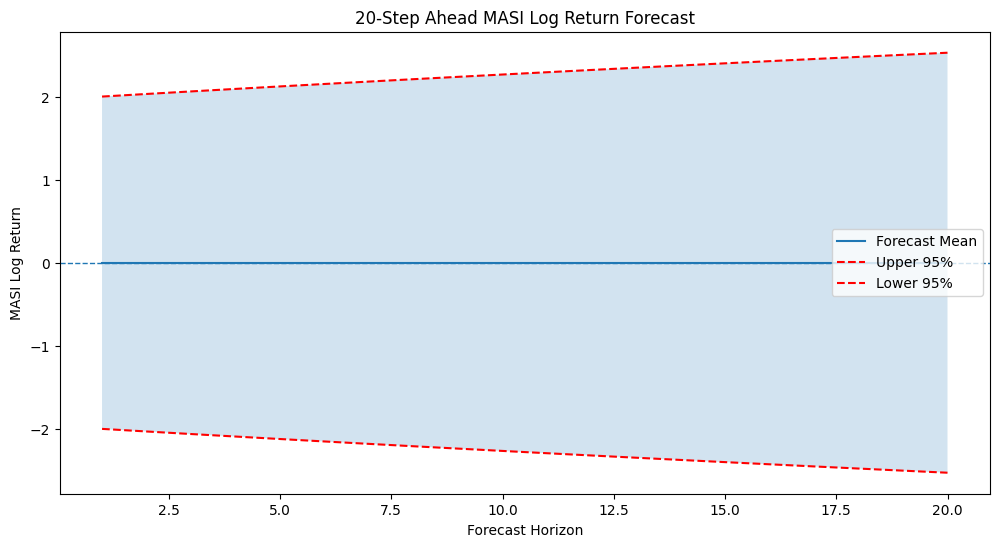

In [28]:
# Plot 20-step ahead return forecast

plt.figure(figsize=(12, 6))

plt.plot(
    forecast_df.index,
    forecast_df["Mean"],
    label="Forecast Mean"
)

plt.plot(
    forecast_df.index,
    forecast_df["Upper 95%"],
    "r--",
    label="Upper 95%"
)

plt.plot(
    forecast_df.index,
    forecast_df["Lower 95%"],
    "r--",
    label="Lower 95%"
)

plt.fill_between(
    forecast_df.index,
    forecast_df["Lower 95%"],
    forecast_df["Upper 95%"],
    alpha=0.2
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.xlabel("Forecast Horizon")
plt.ylabel("MASI Log Return")
plt.title("20-Step Ahead MASI Log Return Forecast")
plt.legend()

plt.show()

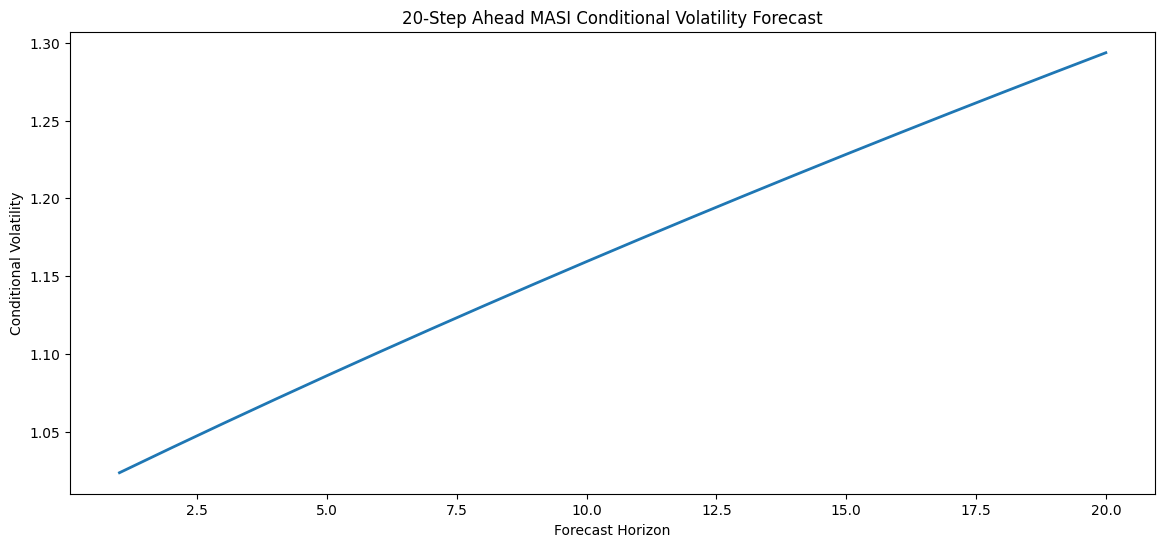

In [29]:
# Plot 20-step ahead volatility forecast

plt.figure(figsize=(14, 6))

plt.plot(
    forecast_df.index,
    forecast_df["Volatility"],
    linewidth=2
)

plt.xlabel("Forecast Horizon")
plt.ylabel("Conditional Volatility")
plt.title("20-Step Ahead MASI Conditional Volatility Forecast")

plt.show()